In [ ]:
#find what kind of noise the recording contains, so the simulator can generate the same kind.
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

HERE = Path.cwd()                           # the notebook's folder (Simulator)
sys.path.insert(0, str(HERE / "src"))
from spike_detection import remove_drift, estimate_noise, detect_spikes

data = np.load(HERE / "data" / "spike_data.npz")
t = data["t"]
raw = data["raw_data"]
fs = 1 / np.median(np.diff(t))

print(f"Loaded {len(raw)} samples at {fs:.0f} Hz from {HERE}")

Loaded 10000 samples at 1000 Hz from /Users/ChloeCook/NeuroData Projects/DS-Advanced Python/Simulator


In [3]:
# Remove the drift
flat = remove_drift(raw, fs)

# Mask out the spikes: ignore 2 ms before to 15 ms after each detected spike
spikes = detect_spikes(raw, fs)
keep = np.ones(len(flat), dtype=bool)           # start with every sample kept (True)
for i in spikes:
    keep[max(i - 2, 0): i + 15] = False         # mark samples near a spike as not kept

noise = flat[keep]                               # only the samples away from spikes

print(f"Spikes masked: {len(spikes)}")
print(f"Samples kept as noise: {keep.sum()} of {len(flat)} ({keep.mean():.0%})")
print(f"Noise mean: {noise.mean():.4f}")
print(f"Noise SD (ordinary): {noise.std():.4f}")
print(f"Noise SD (MAD):      {estimate_noise(noise):.4f}")

Spikes masked: 42
Samples kept as noise: 9297 of 10000 (93%)
Noise mean: -0.0147
Noise SD (ordinary): 0.2991
Noise SD (MAD):      0.2986


Isolate the noise. Removes the slow drift (0.2 s moving median) and masks 2 ms before to 15 ms after each detected spike, leaving 93% of samples as pure noise. Noise SD ~0.30 with both my ordinary SD and MAD agree.

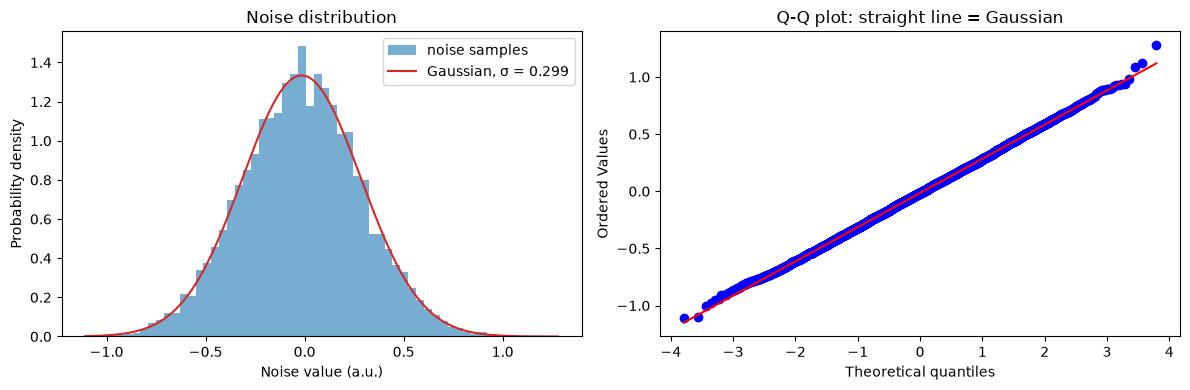

In [6]:
from scipy import stats

sigma = noise.std()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histogram with the matching Gaussian curve
axes[0].hist(noise, bins=60, density=True, alpha=0.6, label="noise samples")
x = np.linspace(noise.min(), noise.max(), 300)
axes[0].plot(x, stats.norm.pdf(x, noise.mean(), sigma), color="tab:red",
             label=f"Gaussian, σ = {sigma:.3f}")
axes[0].set_xlabel("Noise value (a.u.)")
axes[0].set_ylabel("Probability density")
axes[0].set_title("Noise distribution")
axes[0].legend()

# Q-Q plot against a Gaussian
stats.probplot(noise, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q plot: straight line = Gaussian")

plt.tight_layout()
plt.show()

The histogram matches a Gaussian with σ = 0.30, and the Q-Q plot is a straight line across ±3.5 SD, so the noise values are Gaussian

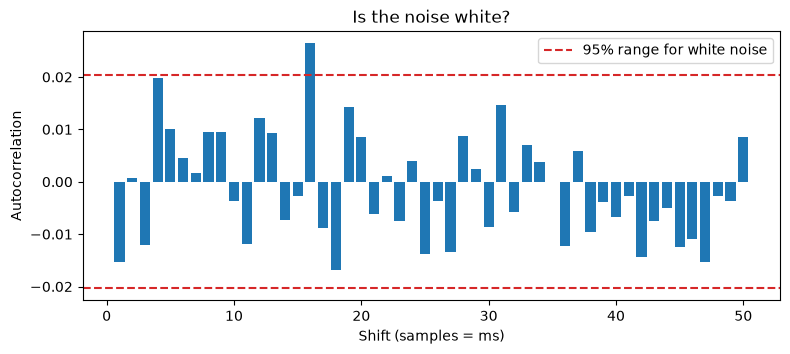

Lag 1: -0.015, lag 20 (50 Hz): 0.008, white-noise range: ±0.020


In [7]:
# Autocorrelation of the noise, using the full drift-removed signal with spikes set to 0
# (keeping the samples in order, so shifts mean real time steps)
x = np.where(keep, flat - flat[keep].mean(), 0.0)

max_lag = 50
acf = [np.sum(x[:-k] * x[k:]) / np.sum(x * x) for k in range(1, max_lag + 1)]
bound = 1.96 / np.sqrt(keep.sum())   # 95% range expected for white noise

plt.figure(figsize=(9, 3.5))
plt.bar(range(1, max_lag + 1), acf)
plt.axhline(bound, color="tab:red", linestyle="--", label="95% range for white noise")
plt.axhline(-bound, color="tab:red", linestyle="--")
plt.xlabel("Shift (samples = ms)")
plt.ylabel("Autocorrelation")
plt.title("Is the noise white?")
plt.legend()
plt.show()

print(f"Lag 1: {acf[0]:.3f}, lag 20 (50 Hz): {acf[19]:.3f}, white-noise range: ±{bound:.3f}")

Correlations between the noise and shifted copies of itself (1–50 ms) are all near zero, with no peak at 20 ms or no 50 Hz line noise. Neighboring samples are independent, so the noise is white

Simulate noise and compare it with the real noise

                  real   simulated
SD              0.2991      0.3005
mean           -0.0147     -0.0025
lag-1 corr     -0.0154      0.0110

KS test, same distribution? p = 0.949


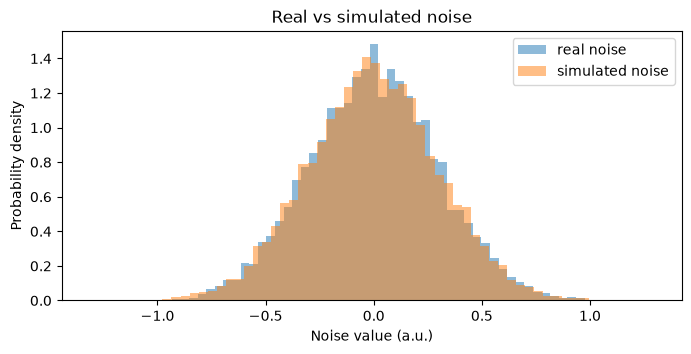

In [8]:
rng = np.random.default_rng(42)                       # seeded: same "random" numbers every run
sim_noise = rng.normal(0, sigma, len(noise))           # fake noise: Gaussian, same sigma, same length

def lag1(x):
    """Correlation between each sample and the next one."""
    x = x - x.mean()
    return np.sum(x[:-1] * x[1:]) / np.sum(x * x)

print(f"{'':12}{'real':>10}{'simulated':>12}")
print(f"{'SD':12}{noise.std():>10.4f}{sim_noise.std():>12.4f}")
print(f"{'mean':12}{noise.mean():>10.4f}{sim_noise.mean():>12.4f}")
print(f"{'lag-1 corr':12}{lag1(x):>10.4f}{lag1(sim_noise):>12.4f}")

ks = stats.ks_2samp(noise - noise.mean(), sim_noise)
print(f"\nKS test, same distribution? p = {ks.pvalue:.3f}")

plt.figure(figsize=(8, 3.5))
plt.hist(noise - noise.mean(), bins=60, density=True, alpha=0.5, label="real noise")
plt.hist(sim_noise, bins=60, density=True, alpha=0.5, label="simulated noise")
plt.xlabel("Noise value (a.u.)")
plt.ylabel("Probability density")
plt.title("Real vs simulated noise")
plt.legend()
plt.show()

Generated Gaussian white noise (σ = 0.30, seed 42) and compared it with the real noise: matching SD, near-zero lag-1 correlation in both, and a KS test showing no evidence of a difference.
